In [2]:
# from benchmarking import BenchmarkingExplainer
# from transformers import AutoModelForSequenceClassification, AutoTokenizer
from XAIbenchmark import XAIFramework
import warnings

warnings.filterwarnings("ignore")

d:\TUM courses\thesis- nlp\Code\myenv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
%load_ext autoreload
%autoreload 2

In [5]:
model_name= "cardiffnlp/twitter-xlm-roberta-base-sentiment"

In [2]:
model_name = "Hate-speech-CNERG/bert-base-uncased-hatexplain"
# model_name= "cardiffnlp/twitter-xlm-roberta-base-sentiment"

In [6]:
xai_framework = XAIFramework(model_name)

Successfully loaded model from: cardiffnlp/twitter-xlm-roberta-base-sentiment


TESTING ON SINGLE SENTENCE

In [96]:
sentence = "I love the product, but the customer service was terrible."
# "I love your style!"

Output classes probabilities

In [97]:
xai_framework.classify_text(sentence)

{'negative': 0.9104563593864441,
 'neutral': 0.05341604724526405,
 'positive': 0.03612753748893738}

Generate Explanations and Visualize

explainer names ['deepLift', 'lime', 'shapiq', 'shap', 'guidedbackprop', 'gradientxinput', 'integratedgradient']


Running Inference: 100%|██████████| 25/25 [00:05<00:00,  4.48it/s]


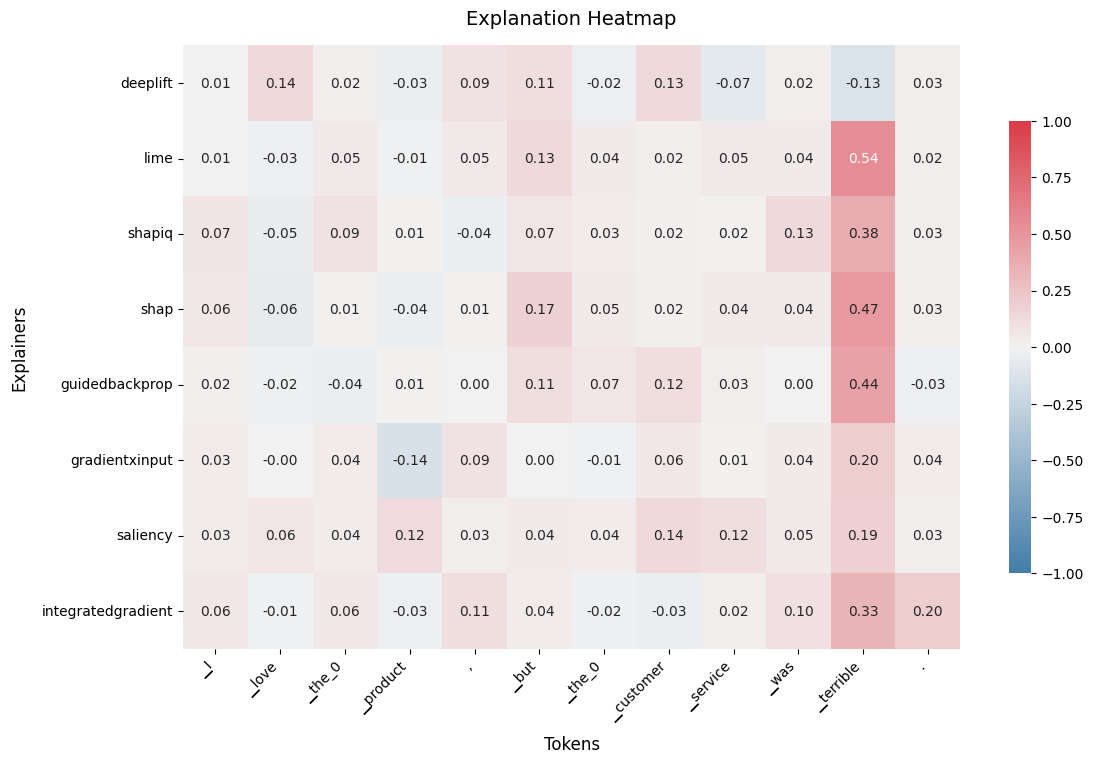

In [98]:
#Here you can define whatever explainers you want to generate scores for
explainer_names=["deepLift","lime","shapiq","shap","guidedbackprop","gradientxinput","integratedgradient"]
# explainer_names=["deepLift"]
exp= xai_framework.explain(sentence,"negative",explainer_names)
xai_framework.visualize(exp)

Metrics Scores

In [111]:
xai_framework.evaluate_single_sentence(sentence, target_label="negative",
                       explainer_names=["deepLift","lime","shapiq","shap","guidedbackprop","integratedgradient", "gradientxinput"],
                       human_rationale=[0, 1, 0, 1, 0,0,0,0,1,0,1,0])
                                        # "lime","shapiq","shap","guidedbackprop","integratedgradient"],
                    #    evaluator_names=["softcomprehensiveness", "fad","iou"],)
                                        # "softsufficiency","fad","auprc","iou","complexity","sparseness"],
                    

explainer <explainers.deeplift.DeepLiftExplainer object at 0x000001E95F535CA0>
evaluator <evaluators.softcomprehensiveness.SoftComprehensivenessEvaluator object at 0x000001E95F535B80>
[Explanation(text=['I love the product, but the customer service was terrible.'], tokens=['<s>', '▁I', '▁love', '▁the', '▁product', ',', '▁but', '▁the', '▁customer', '▁service', '▁was', '▁terrible', '.', '</s>'], scores=array([-0.1493776 ,  0.00622407,  0.13692947,  0.0186722 , -0.03319502,
        0.09128631,  0.10788382, -0.02489627,  0.13278009, -0.07053942,
        0.02489627, -0.13278009,  0.02904564,  0.04149378], dtype=float32), explainer='deeplift', target_pos_idx=0, target_token_pos_idx=None, target='negative', target_token=None, rationale=[0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0])]
evaluator <evaluators.softsufficiency.SoftSufficiencyEvaluator object at 0x000001E95F535D30>
0
evaluator <evaluators.FAD.FADEvaluator object at 0x000001E95F5355E0>
evaluator <evaluators.complexity.ComplexityEvaluator objec

Running Inference: 100%|██████████| 25/25 [00:05<00:00,  4.19it/s]


evaluator <evaluators.softcomprehensiveness.SoftComprehensivenessEvaluator object at 0x000001E959C40700>
[Explanation(
  text=['I love the product, but the customer service was terrible.'],
  tokens=['<s>', '▁I', '▁love', '▁the', '▁product', ',', '▁but', '▁the', '▁customer', '▁service', '▁was', '▁terrible', '.', '</s>'],
  scores=[ 0.          0.00740469 -0.03366688  0.00121457  0.00129042  0.0413234
  0.16352091  0.07051003  0.02689637  0.03679833  0.038438    0.51882939
  0.060107    0.        ],
  explainer=lime,
  target=negative,
)]
evaluator <evaluators.softsufficiency.SoftSufficiencyEvaluator object at 0x000001E95F535E50>
0
evaluator <evaluators.FAD.FADEvaluator object at 0x000001E95F535B20>
evaluator <evaluators.complexity.ComplexityEvaluator object at 0x000001E95F535910>
evaluator <evaluators.sparseness.SparsenessEvaluator object at 0x000001E95F535760>
evaluator <evaluators.AUPRC.AUPRCEvaluator object at 0x000001E95F535CA0>
evaluator <evaluators.IOU.IOUEvaluator object at 0x00

Evaluator,AUPRCEvaluator,ComplexityEvaluator,FADEvaluator,SoftComprehensivenessEvaluator,SoftSufficiencyEvaluator,SparsenessEvaluator
Explainer,,,,,,
deeplift,0.423737,0.169709,1.00,0.563740,0.000176,0.248963
gradientxinput,0.440142,0.156960,0.50,0.563742,0.000176,0.363656
guidedbackprop,0.518155,0.136688,0.25,0.462305,0.000175,0.466892
integratedgradient,0.454978,0.145408,0.25,0.563736,0.000175,0.436611
lime,0.447583,0.116820,0.25,0.584031,0.000177,0.556160
saliency,0.766667,0.174681,0.25,0.462305,0.000177,0.200437
shap,0.451515,0.129194,0.25,0.426422,0.000172,0.491863
shapiq,0.440142,0.160178,0.25,0.583070,0.000174,0.304618


TESTING ON ENTIRE DATASET/ SUB SAMPLE

In [6]:
from dataset_loaders.dataset_loader import LoadDatasetArgs,load_fields_from_dataset

dataset_args_ = LoadDatasetArgs( # Path to the dataset file
    # dataset_name= "csv",
    dataset_name="eraser-benchmark/movie_rationales",
    input_text_field="review",  # Assuming "text" column contains the text data
    label_field="label",  # Assuming "label" column contains the sentiment labels
    rationale_field="evidences",
    dataset_split="test",  # Assuming you want to load the test split
    # dataset_files=["healthFC_annotated.csv"]
)

# Load the dataset fields
input_texts, labels, rationale = load_fields_from_dataset(dataset_args_)

In [6]:
input_texts_sample=input_texts[100:115] 
labels_sample=labels[100:115]
rationale_sample= rationale[100:115] 

In [25]:
len(rationale_sample)

150

In [ ]:
xai_framework.generate_explainer_table_for_dataset(input_texts_sample, labels_sample,rationales=rationale_sample,explainer_names=["deeplift","gradientxinput","guidedbackprop","integratedgradient"])

Checking individual Metrics

In [25]:
from transformers import AutoModelForSequenceClassification, AutoTokenizer

name = "cardiffnlp/twitter-xlm-roberta-base-sentiment"
# name = "Hate-speech-CNERG/bert-base-uncased-hatexplain"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name)


In [6]:
from dataset_loaders import HateXplain
hateXplain = HateXplain(tokenizer)

In [ ]:
hateXplain._get_text()

<bound method HateXplain._get_text of <dataset_loaders.hatexplain.HateXplain object at 0x000001E30CAB4220>>

In [8]:
from dataset_loaders.dataset_loader import LoadDatasetArgs,load_fields_from_dataset

dataset_args_ = LoadDatasetArgs( # Path to the dataset file
    # dataset_name= "csv",
    dataset_name="Hate-speech-CNERG/hatexplain",
    input_text_field="post_tokens",  # Assuming "text" column contains the text data
    label_field="annotators",  # Assuming "label" column contains the sentiment labels
    rationale_field="rationales",
    dataset_split="test",  # Assuming you want to load the test split
    # dataset_files=["healthFC_annotated.csv"]
)

# Load the dataset fields
input_texts, labels, rationale = load_fields_from_dataset(dataset_args_)

In [9]:
# # Now extract the label from the first annotator for each example
processed_labels = [int(annotators['label'][0]) if annotators else None 
                    for annotators in labels]

In [10]:
import numpy as np
def token_list_to_string(text_field):
    if isinstance(text_field, (list, np.ndarray)):  # Handle both lists and numpy arrays
        return " ".join(map(str, text_field))  # Join the tokens into a single string
    return str(text_field)  # In case text_field is already a string, just return it

#processed_text = [token_list_to_string(text) if text else None for text in input_texts]
processed_text = [token_list_to_string(text) if len(text) > 0 else None for text in input_texts]
processed_text[0]

'<user> men can not be raped can not be abused that why they call it violence against women and children because men are always the perpetrators women come first even before children'

In [11]:
input_texts_sample=processed_text[15:30] 
labels_sample=processed_labels[15:30]
rationale_sample= rationale[15:30] 

print(type(input_texts))
print(type(labels_sample))
print(type(rationale))

<class 'list'>
<class 'list'>
<class 'list'>


In [12]:
rationale_sample = [
    arr[0] if len(arr) > 0 and len(arr[0]) > 0 else None
    for arr in rationale_sample
]

Processing instance 0
Found cached explanation for deeplift
Processing instance 1
Found cached explanation for deeplift
Processing instance 2
Found cached explanation for deeplift
Processing instance 3
Found cached explanation for deeplift
Processing instance 4
Found cached explanation for deeplift
Processing instance 5
Found cached explanation for deeplift
Processing instance 6
Found cached explanation for deeplift
Processing instance 7
Found cached explanation for deeplift
Processing instance 8
Found cached explanation for deeplift
Processing instance 9
Found cached explanation for deeplift
Processing instance 10
Found cached explanation for deeplift
Processing instance 11
Found cached explanation for deeplift
Processing instance 12
Found cached explanation for deeplift


BertSdpaSelfAttention is used but `torch.nn.functional.scaled_dot_product_attention` does not support non-absolute `position_embedding_type` or `output_attentions=True` or `head_mask`. Falling back to the manual attention implementation, but specifying the manual implementation will be required from Transformers version v5.0.0 onwards. This warning can be removed using the argument `attn_implementation="eager"` when loading the model.


Processing instance 13
Found cached explanation for deeplift
Processing instance 14
Found cached explanation for deeplift
SoftComprehensivenessEvaluator
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
SoftSufficiencyEvaluator
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
FADEvaluator
percent to drop 0
percent to drop 10
percent to drop 20
percent to drop 30
percent to drop 40


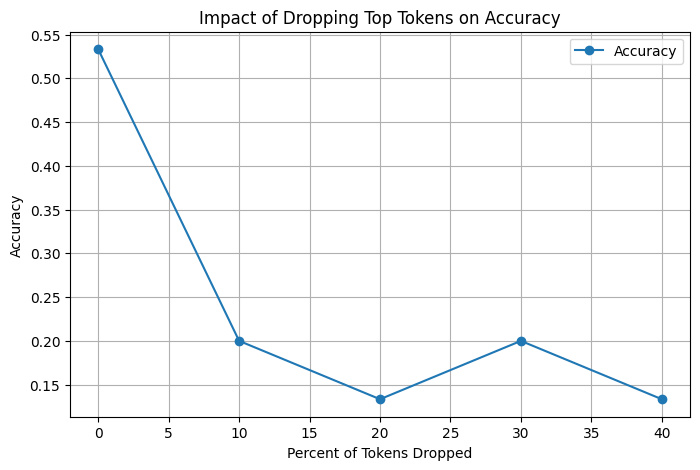

ComplexityEvaluator
SparsenessEvaluator
Processing instance 0
Found cached explanation for gradientxinput
Found cached explanation for saliency
Processing instance 1
Found cached explanation for gradientxinput
Found cached explanation for saliency
Processing instance 2
Found cached explanation for gradientxinput
Found cached explanation for saliency
Processing instance 3
Found cached explanation for gradientxinput
Found cached explanation for saliency
Processing instance 4
Found cached explanation for gradientxinput
Found cached explanation for saliency
Processing instance 5
Found cached explanation for gradientxinput
Found cached explanation for saliency
Processing instance 6
Found cached explanation for gradientxinput
Found cached explanation for saliency
Processing instance 7
Found cached explanation for gradientxinput
Found cached explanation for saliency
Processing instance 8
Found cached explanation for gradientxinput
Found cached explanation for saliency
Processing instance 9
Fo

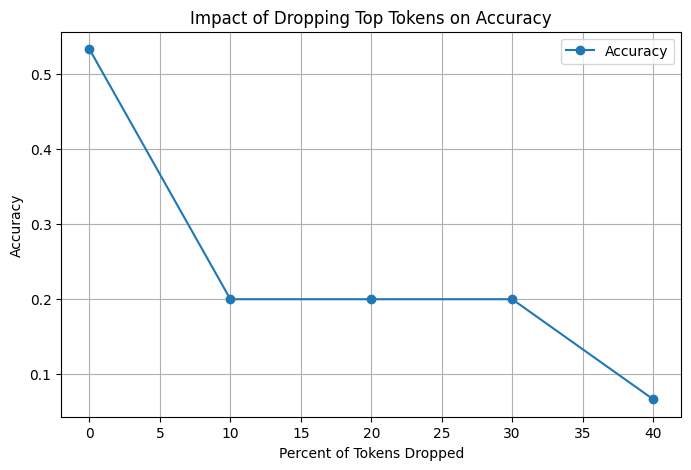

ComplexityEvaluator
SparsenessEvaluator
SoftComprehensivenessEvaluator
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
SoftSufficiencyEvaluator
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
FADEvaluator
percent to drop 0
percent to drop 10
percent to drop 20
percent to drop 30
percent to drop 40


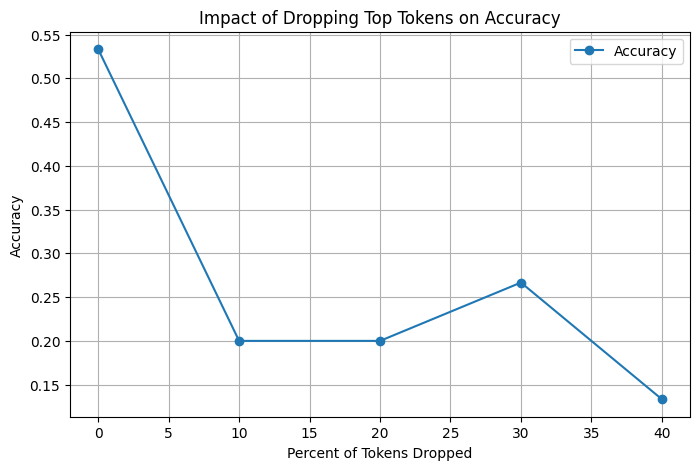

ComplexityEvaluator
SparsenessEvaluator
Processing instance 0
Found cached explanation for guidedbackprop
Processing instance 1
Found cached explanation for guidedbackprop
Processing instance 2
Found cached explanation for guidedbackprop
Processing instance 3
Found cached explanation for guidedbackprop
Processing instance 4
Found cached explanation for guidedbackprop
Processing instance 5
Found cached explanation for guidedbackprop
Processing instance 6
Found cached explanation for guidedbackprop
Processing instance 7
Found cached explanation for guidedbackprop
Processing instance 8
Found cached explanation for guidedbackprop
Processing instance 9
Found cached explanation for guidedbackprop
Processing instance 10
Found cached explanation for guidedbackprop
Processing instance 11
Found cached explanation for guidedbackprop
Processing instance 12
Found cached explanation for guidedbackprop
Processing instance 13
Found cached explanation for guidedbackprop
Processing instance 14
Found cac

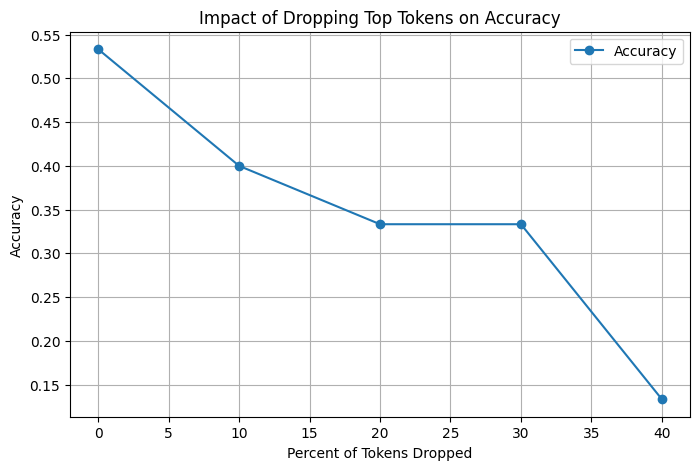

ComplexityEvaluator
SparsenessEvaluator
Processing instance 0
Found cached explanation for integratedgradient
Processing instance 1
Found cached explanation for integratedgradient
Processing instance 2
Found cached explanation for integratedgradient
Processing instance 3
Found cached explanation for integratedgradient
Processing instance 4
Found cached explanation for integratedgradient
Processing instance 5
Found cached explanation for integratedgradient
Processing instance 6
Found cached explanation for integratedgradient
Processing instance 7
Found cached explanation for integratedgradient
Processing instance 8
Found cached explanation for integratedgradient
Processing instance 9
Found cached explanation for integratedgradient
Processing instance 10
Found cached explanation for integratedgradient
Processing instance 11
Found cached explanation for integratedgradient
Processing instance 12
Found cached explanation for integratedgradient
Processing instance 13
Found cached explanation

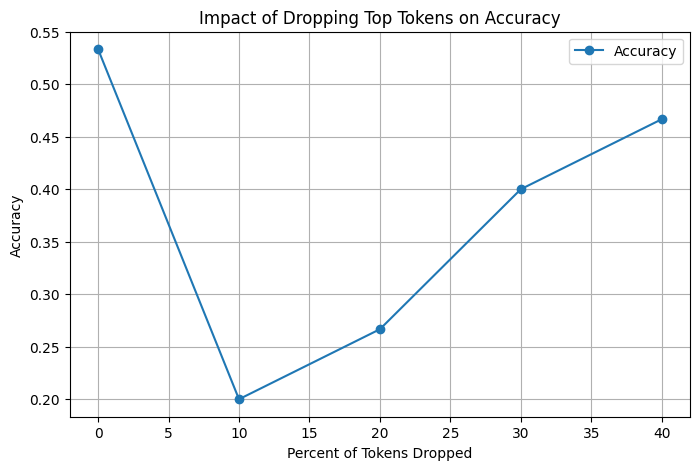

ComplexityEvaluator
SparsenessEvaluator
{'deeplift': {'SoftComprehensivenessEvaluator': np.float32(0.26278153), 'SoftSufficiencyEvaluator': np.float32(0.5349239), 'FADEvaluator': np.float64(0.5000000000000001), 'ComplexityEvaluator': np.float64(0.1244647213969733), 'SparsenessEvaluator': 0.7700182199478149}, 'gradientxinput': {'SoftComprehensivenessEvaluator': np.float32(0.2616928), 'SoftSufficiencyEvaluator': np.float32(0.53382987), 'FADEvaluator': np.float64(0.5312500000000001), 'ComplexityEvaluator': np.float64(0.13796334800813367), 'SparsenessEvaluator': 0.714186429977417}, 'guidedbackprop': {'SoftComprehensivenessEvaluator': np.float32(0.26230747), 'SoftSufficiencyEvaluator': np.float32(0.53371733), 'FADEvaluator': np.float64(0.7812500000000001), 'ComplexityEvaluator': np.float64(0.12453091432862375), 'SparsenessEvaluator': 0.770268440246582}, 'integratedgradient': {'SoftComprehensivenessEvaluator': np.float32(0.26284933), 'SoftSufficiencyEvaluator': np.float32(0.53656214), 'FADEv

Evaluator,ComplexityEvaluator,FADEvaluator,SoftComprehensivenessEvaluator,SoftSufficiencyEvaluator,SparsenessEvaluator
Explainer,,,,,
deeplift,0.124465,0.50000,0.262782,0.534924,0.770018
gradientxinput,0.137963,0.53125,0.261693,0.533830,0.714186
guidedbackprop,0.124531,0.78125,0.262307,0.533717,0.770268
integratedgradient,0.128169,0.56250,0.262849,0.536562,0.755870


In [15]:
xai_framework.generate_explainer_table_for_dataset(input_texts_sample, labels_sample,rationales=rationale_sample,explainer_names=["deeplift","gradientxinput","guidedbackprop","integratedgradient"])

In [ ]:
exps= xai_framework.get_feature_importance_for_dataset(input_texts_sample, labels_sample,rationales=rationale_sample,explainer_names=["lime"])

Processing instance 0


Running Inference: 100%|██████████| 85/85 [01:30<00:00,  1.06s/it]


Processing instance 1


Running Inference:  62%|██████▏   | 113/181 [04:43<02:37,  2.32s/it]

In [ ]:
x= exps['lime']
x

[Explanation(
   text=['there too many wypipo asking what this is and if they can get in this is a niggers only event'],
   tokens=['<s>', '▁there', '▁too', '▁many', '▁wy', 'pi', 'po', '▁asking', '▁what', '▁this', '▁is', '▁and', '▁if', '▁they', '▁can', '▁get', '▁in', '▁this', '▁is', '▁a', '▁ni', 'gger', 's', '▁only', '▁event', '</s>'],
   scores=[ 0.01020607  0.04727555  0.04978638  0.06987229  0.01514587  0.00352692
   0.00476262  0.04174695  0.04168142  0.07701843  0.05994813  0.03616033
   0.03322876  0.14219059  0.07811158  0.04895578  0.0114732   0.03152028
   0.06008989  0.03285297  0.05328796 -0.00860502 -0.01246937  0.02155231
   0.00375017  0.00478114],
   explainer=shapiq,
   target=negative,
 ),
 Explanation(
   text=['<user> <user> nothing more than serial rapists both of them he raped women and american taxpayers and she raped america and the american taxpayer'],
   tokens=['<s>', '▁<', 'user', '>', '▁<', 'user', '>', '▁nothing', '▁more', '▁than', '▁serial', '▁rap', 'ists'

In [127]:
from evaluators.FAD import FADEvaluator
from evaluators.faithfulness_auc import AUC_TPEvaluator
from evaluators.IOU import IOUEvaluator
from evaluators.AUPRC import AUPRCEvaluator
from evaluators.softcomprehensiveness import SoftComprehensivenessEvaluator
from evaluators.softsufficiency import SoftSufficiencyEvaluator
from evaluators.monotonicity import MonotonicityEvaluator
from evaluators.complexity import ComplexityEvaluator
from evaluators.sparseness import SparsenessEvaluator

fad= FADEvaluator(model, tokenizer, x)
fad.compute()

# auc= AUC_TPEvaluator(model, tokenizer, exps)
# auc.compute()

# sc= SoftComprehensivenessEvaluator(model, tokenizer, x)
# sc.compute()

# ss= SoftSufficiencyEvaluator(model, tokenizer, exps)
# ss.compute()

# monotonicity= MonotonicityEvaluator(model, tokenizer, exp)
# monotonicity.compute()

# complexity= ComplexityEvaluator(model, tokenizer, exp)
# complexity.compute()

# iou= IOUEvaluator(model, tokenizer, exp)
# iou= iou.compute()

# auprc= AUPRCEvaluator(model, tokenizer, exps)
# auprc= auprc.compute()

# sparseness= SparsenessEvaluator(model, tokenizer, exps)
# sparseness.compute()

np.float64(0.9000000000000001)

In [107]:
y= exps[5]
y

Explanation(
  text=['I love the product, but the customer service was terrible.'],
  tokens=['<s>', '▁I', '▁love', '▁the', '▁product', ',', '▁but', '▁the', '▁customer', '▁service', '▁was', '▁terrible', '.', '</s>'],
  scores=[ 0.          0.01416108  0.00363614  0.01137063 -0.02397475 -0.00398393
  0.15111319  0.02041471  0.0435243   0.11348504  0.08164228  0.49741307
  0.03528088  0.        ],
  explainer=lime,
  target=negative,
)


1️⃣ Identify Key Words Driving the Prediction 🎯

Looking at the heatmap, we see that "terrible" is consistently marked red across most methods (LIME, SHAP, Guided Backprop, etc.).

✅ This confirms that the model is strongly associating "terrible" with its final decision (likely negative sentiment)

However, we also see that some methods assign importance to "customer" and "service"—which may or may not be relevant.

📌 User Action: If words like "customer" or "service" are wrongly influencing sentiment, the model might be learning unintended biases.

2️⃣ Check Explanation Consistency Across Methods 📊

By comparing rows, we see that some methods (LIME, SHAP, SHAPIQ, Guided Backprop) strongly highlight "terrible," while others (Gradient Input, Saliency) assign lower importance.

✅ If multiple methods agree on important words (e.g., "terrible"), we can trust the explanation.

⚠️ If one method (e.g., Gradient Input) highlights unexpected words, it may not be reliable in this case.

📌 User Action: Choose the most stable explanation method based on consistency.

3️⃣ Detect Model Bias or Incorrect Behavior 🎭

If the model is over-relying on neutral words, it may be learning patterns incorrectly.

🔍 The heatmap shows that some methods (e.g., GradientxInput, Guided Backprop) assign importance to "customer" and "service", which should ideally be neutral.

✅ This could indicate that the model associates customer service with negative sentiment, potentially due to biased training data.

📌 User Action: If bias is detected, retrain the model with more balanced examples.

4️⃣ Understanding Token-Level Sentiment Contributions 📝
Each word's importance helps users understand how the model processes language.

"Love" has a low positive score (indicating it contributes to positive sentiment).

"But" has almost neutral influence (as expected in contrastive phrases).

"Terrible" has a strong negative impact, confirming it drives the negative prediction.

📌 User Action: Use heatmaps to validate that words influencing predictions align with human intuition.
